# Milestone 3 Data visualization

## Task 1: Monthly Revenue Trend Chart

In [2]:
# Setup

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from pathlib import Path

# Find the workbook from the project root or any folder within the project.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "Coffee Shop Sales.xlsx").is_file()),
    None
)
if project_root is None:
    raise FileNotFoundError(
        "Open the notebook from the Coffee Shop Analysis project folder "
        "or a folder inside it. Expected data/Coffee Shop Sales.xlsx."
    )
df = pd.read_excel(project_root / "data" / "Coffee Shop Sales.xlsx")
df["line_revenue"] = df["transaction_qty"] * df["unit_price"]
df["month"] = pd.to_datetime(df["transaction_date"]).dt.to_period('M')
df["time_of_day"] = df["transaction_time"].apply(lambda t: t.hour)



month
2023-01     81677.74
2023-02     76145.19
2023-03     98834.68
2023-04    118941.08
2023-05    156727.76
2023-06    166485.88
Freq: M, Name: line_revenue, dtype: float64

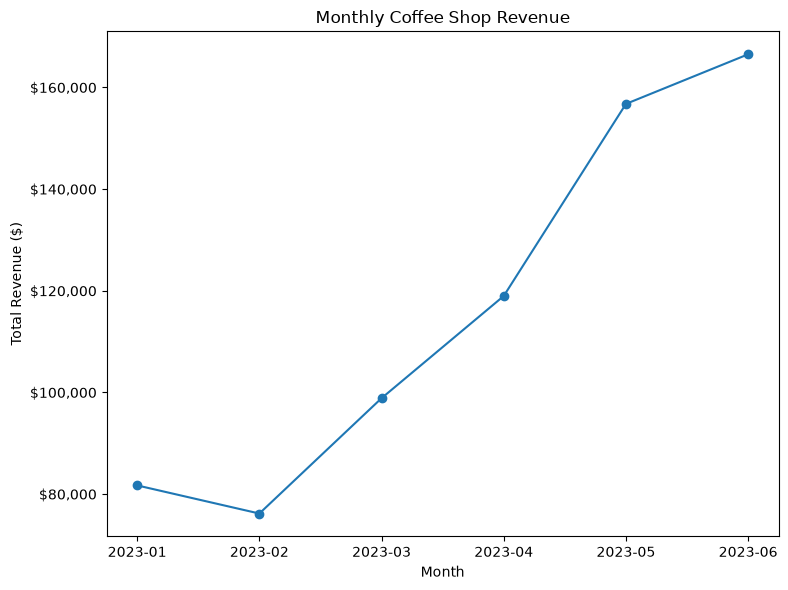

In [3]:
# Task 1: Monthly Revenue Trend Chart

total_revenue_monthly = df.groupby("month")["line_revenue"].sum().sort_index()
display(total_revenue_monthly)

plt.figure(figsize=(8, 6))

plt.plot(
    total_revenue_monthly.index.astype(str),
    total_revenue_monthly.values,
    marker="o"
)

plt.title("Monthly Coffee Shop Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")

# Step 5: Format the Y-axis as dollars
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)


# Step 6: Display the chart
plt.tight_layout()
plt.show()


In [4]:
monthly_comparison = total_revenue_monthly.to_frame(name = "revenue").reset_index()
monthly_comparison["calendar_days"] = monthly_comparison["month"].dt.days_in_month
monthly_comparison["revenue_per_day"] = monthly_comparison["revenue"]/monthly_comparison["calendar_days"]
monthly_comparison["revenue_change_pct"] = (
    monthly_comparison["revenue"].pct_change() * 100
)
monthly_comparison["daily_revenue_change_pct"] = (
    monthly_comparison["revenue_per_day"].pct_change() * 100
)
monthly_comparison



,month,revenue,calendar_days,revenue_per_day,revenue_change_pct,daily_revenue_change_pct
0,2023-01,81677.74,31,2634.765806,NaN,NaN
1,2023-02,76145.19,28,2719.471071,-6.773633,3.214907
2,2023-03,98834.68,31,3188.215484,29.797667,17.236602
3,2023-04,118941.08,30,3964.702667,20.343466,24.354915
4,2023-05,156727.76,31,5055.734194,31.769242,27.518622
5,2023-06,166485.88,30,5549.529333,6.226159,9.767031


### How did total revenue change from January to February, in dollars and percentage terms?
Revenue fell from $81,677.74 in January to $76,145.19 in February, a decrease of $5,532.55, or 6.77%.

### How many calendar days were in each month, and why does this matter when comparing monthly totals?
January had 31 days and February had 28. Different month lengths affect the time available to generate revenue. Comparing revenue per calendar day helps account for this difference.

### What was the average revenue per calendar day in each month, and what was the percentage change?
Revenue per calendar day was $2,634.77 in January, $2,719.47 in February, $3,188.22 in March, $3,964.70 in April, $5,055.73 in May, and $5,549.53 in June. The month-over-month changes were +3.21%, +17.24%, +24.35%, +27.52%, and +9.77%, respectively. January has no preceding month in this dataset for comparison.

### How can February have lower total revenue but higher revenue per calendar day? What does each measure tell management?
Monthly total revenue measures sales over the whole month. Revenue per calendar day measures the average daily sales rate. February's daily rate increased, but the month had three fewer days, so the higher daily rate did not offset the shorter month.

### How would you describe the overall January-June revenue trend while accurately acknowledging the February exception?
Total monthly revenue increased overall from January to June, with a February decline followed by increases each month through June. Revenue per calendar day increased every month. These observations describe this period and do not establish annual seasonality or explain the causes of growth.


## Task 2: Coffee Shop Revenue by Location Chart

store_location
Lower Manhattan    230057.25
Astoria            232243.91
Hell's Kitchen     236511.17
Name: line_revenue, dtype: float64

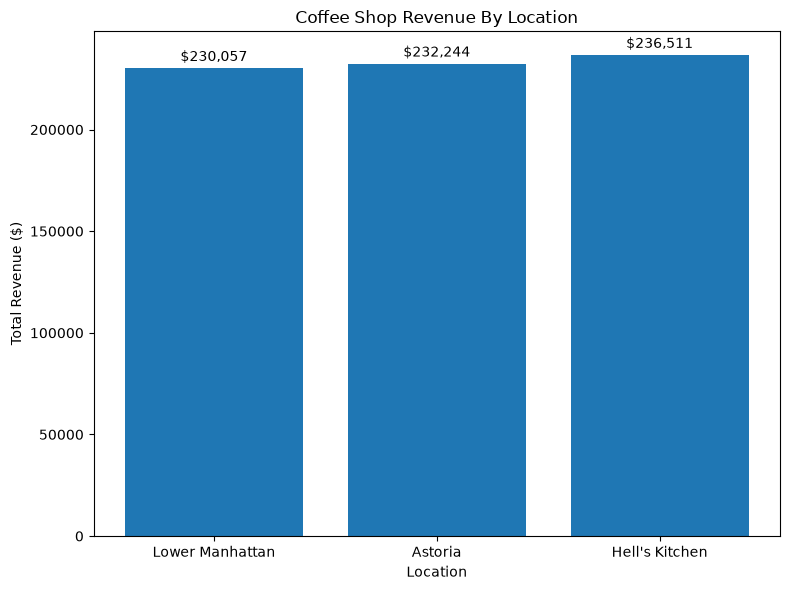

In [5]:
revenue_by_location = df.groupby("store_location")["line_revenue"].sum().sort_values()
display(revenue_by_location)

plt.figure(figsize=(8, 6))

bars = plt.bar(
    revenue_by_location.index,
    revenue_by_location.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_location.values],
    padding=3
)

plt.title("Coffee Shop Revenue By Location")
plt.xlabel("Location")
plt.ylabel("Total Revenue ($)")


plt.tight_layout()
plt.show()


### Which store generates the highest revenue?
Hell's Kitchen generates the highest revenue at $236,511.17.

### What is the dollar difference between the highest- and lowest-performing stores?
Hell's Kitchen generates $6,453.92 more than Lower Manhattan, which records $230,057.25.

### Does the highest-revenue store necessarily have the most transactions?
Revenue depends on both transaction volume and average transaction value. In this dataset, Hell's Kitchen leads both revenue and recorded transaction count, with 50,735 distinct transaction IDs. This relationship need not hold in every business or period.


## Task 3: Top 10 Products by Revenue Chart

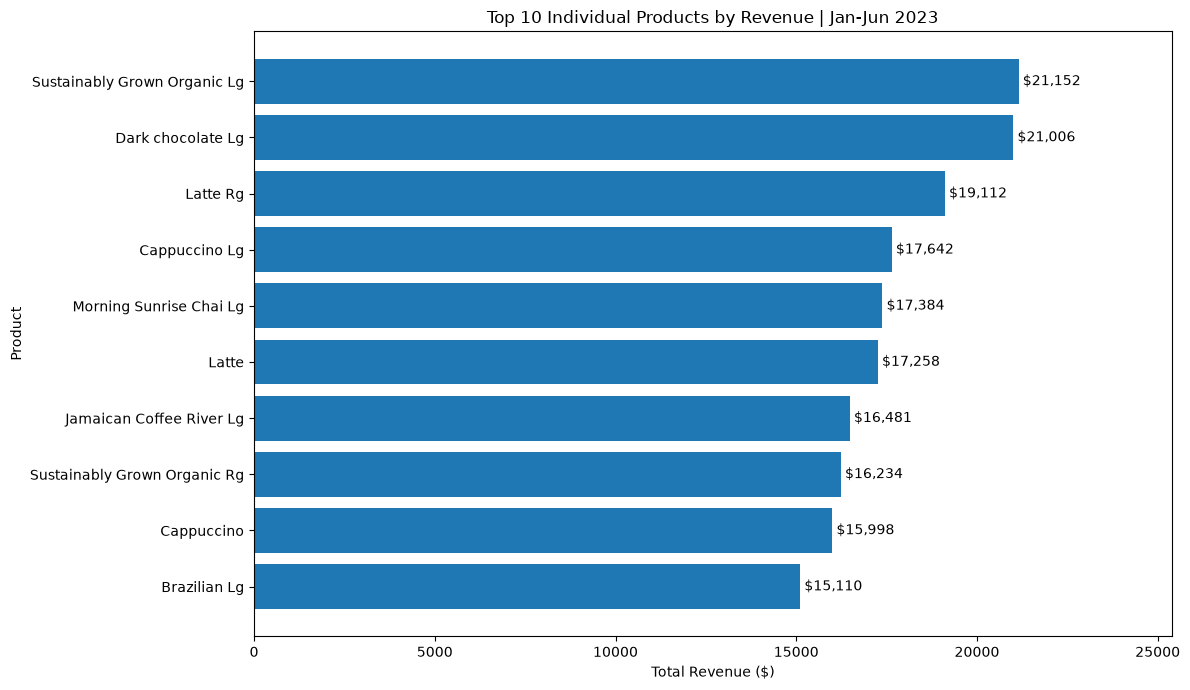

In [6]:
revenue_by_product = df.groupby("product_detail")["line_revenue"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    revenue_by_product.index,
    revenue_by_product.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_product.values],
    padding=3
)

plt.xlim(0, revenue_by_product.max() * 1.2)

plt.gca().invert_yaxis()
plt.title("Top 10 Individual Products by Revenue | Jan-Jun 2023")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


### Which individual product generates the most revenue?

Sustainably Grown Organic Lg generates the most revenue, totaling $21,151.75 across January–June 2023.

### How much revenue does it generate compared with the 10th-ranked product?

Brazilian Lg ranks tenth with $15,109.50 in revenue. Sustainably Grown Organic Lg generates $6,042.25 more.

### Does generating the most revenue necessarily mean a product sells the most units?

No. Revenue depends on both the number of units sold and their prices. A higher-priced product can generate more revenue while selling fewer units.

## Task 4: Busiest Hours by Store Chart

,store_location,time_of_day,transactions
3,Astoria,10,5291
2,Astoria,9,5083
1,Astoria,8,4966
0,Astoria,7,4181
9,Astoria,16,3599
12,Astoria,19,3565
11,Astoria,18,3463
6,Astoria,13,3456
5,Astoria,12,3438
8,Astoria,15,3423


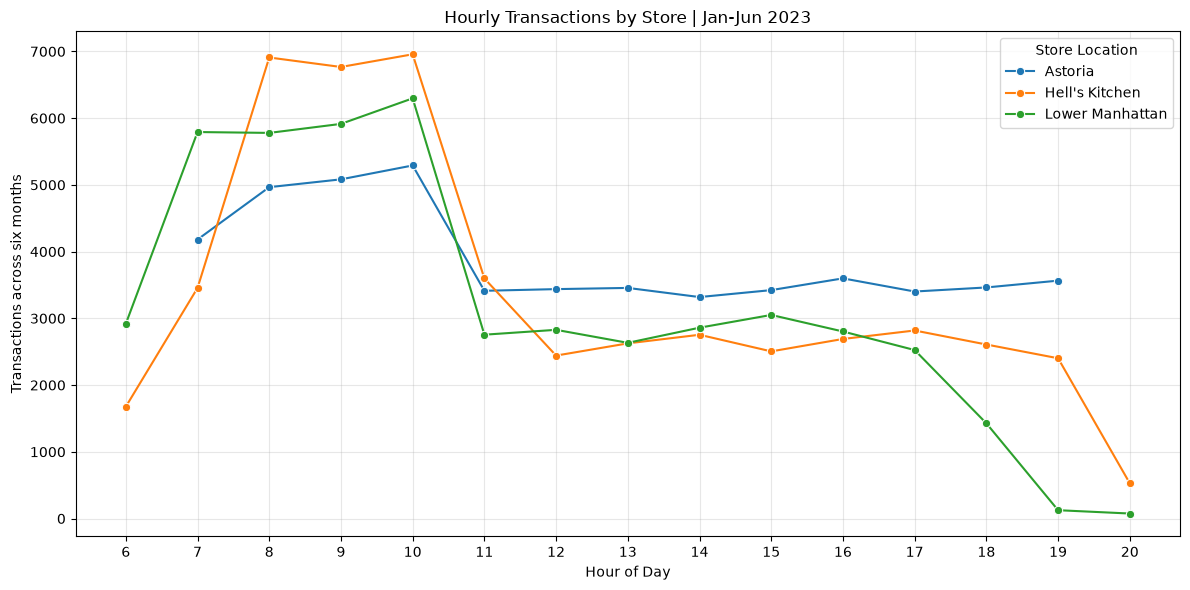

In [7]:
store_hour = (
    df.groupby(["store_location", "time_of_day"])["transaction_id"]
    .nunique()
    .reset_index(name="transactions")
    .sort_values(
        by=["store_location", "transactions"],
        ascending=[True, False]
    ) 
)

display(store_hour)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=store_hour,
    x="time_of_day",
    y="transactions",
    hue="store_location",
    marker="o"
)

plt.title("Hourly Transactions by Store | Jan-Jun 2023")
plt.xlabel("Hour of Day")
plt.ylabel("Transactions across six months")

plt.xticks(sorted(store_hour["time_of_day"].unique()))
plt.legend(title="Store Location")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Which store has the highest peak-hour transaction count?

Hell's Kitchen has the highest count, with 6,957 transactions recorded in the 10:00–10:59 AM bucket across January–June 2023.

### Do all three locations experience their busiest period around the same time?

All three locations reach their highest aggregate hourly transaction count at 10 AM, followed by a sharp drop at 11 AM. Afternoon activity fluctuates by store. Astoria remains relatively steady, while Hell's Kitchen and Lower Manhattan also experience afternoon rebounds.

### Which store experiences the sharpest decline after its morning peak?

Lower Manhattan has the largest immediate decline, falling from 6,297 transactions at 10 AM to 2,755 at 11 AM. This is a decrease of 3,542 transactions, or 56.25%.

### What staffing recommendation would you make based on these patterns?

Management should review morning staffing coverage at each location. Before making changes, it should confirm operating hours and examine existing staffing, customer wait times, and labor costs. If service bottlenecks are observed, a limited staffing trial could test whether additional coverage improves service at an acceptable cost.

## Task 5: Revenue Share by Product Category

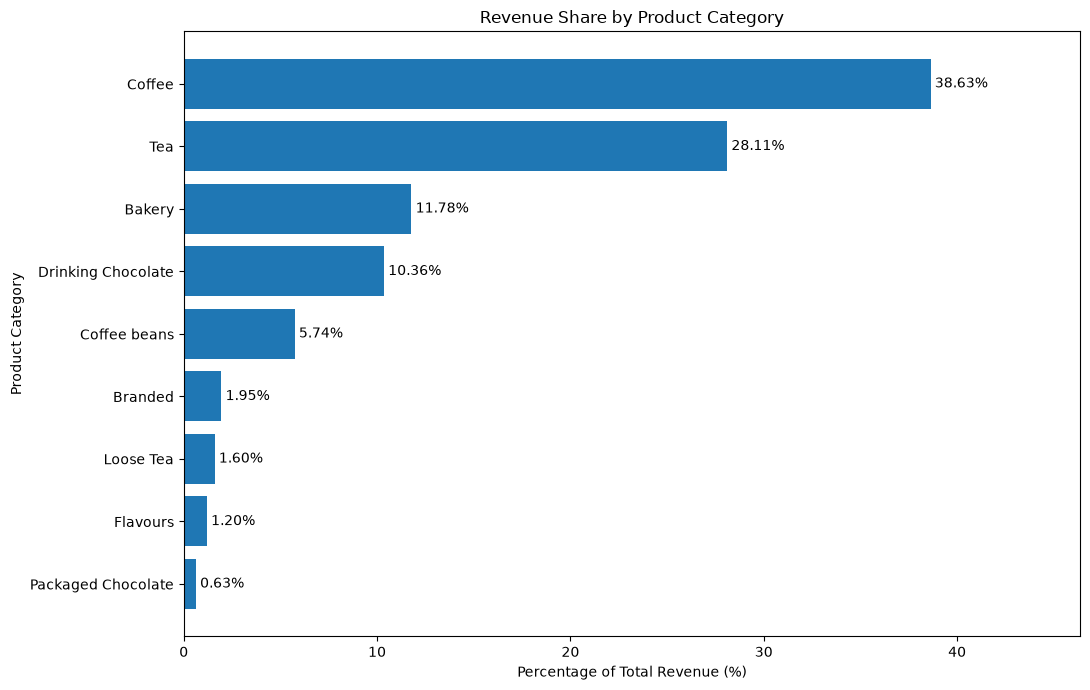

In [8]:
temp = df.groupby("product_category")["line_revenue"].sum().sort_values(ascending=False)
temp = temp.to_frame(name = "revenue")
temp["percentage"] = (
    temp["revenue"] / temp["revenue"].sum() * 100
).round(2)
temp = temp.sort_values(by = "percentage")
# Create the chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    temp.index,
    temp["percentage"]
)

plt.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in temp["percentage"]],
    padding=3
)

# Add chart title and axis labels
plt.title("Revenue Share by Product Category")
plt.xlabel("Percentage of Total Revenue (%)")
plt.ylabel("Product Category")

plt.xlim(0, temp["percentage"].max() * 1.2)
plt.tight_layout()
plt.show()


### Which category contributes the most revenue?
Coffee contributes $269,952.45, or 38.63% of total sales revenue.

### What percentage of revenue comes from Coffee and Tea combined?
Coffee and Tea together account for 66.74% of total revenue.

### What does this suggest about the business's dependence on those two categories?
These categories contribute about two-thirds of recorded revenue. Changes in their availability, prices, or sales could materially affect total revenue. Revenue concentration does not establish profitability or the causes of customer purchases.

### What recommendation would you make to management?
Review inventory availability for leading Coffee and Tea products using stockout history, replenishment lead times, and margins. A beverage-and-bakery bundle could be tested, but its effect is unproven. This dataset has no separate receipt identifier establishing complete baskets, so co-purchases and incremental bundle sales would require additional data and a measured trial.
